# Robustness to nuisance parameters

The Fisher $\sigma_{A_B}$ and $\chi^2_{\min}$ of the bias analysis hold for a fixed geometry and a phase curve without further terms. A real analysis marginalises over the transit geometry and usually fits ellipsoidal terms. Every such nuisance is one more column of the same linear least-squares problem (`simple_bias_analysis`, "Robustness to nuisance parameters"), linearised around the noiseless $A_B$-only fit in whitened units, each column with its mean removed per detector (the free baseline):
$$\delta = \arg\min\ \lVert r_\perp - X\delta\rVert^2 + \sum_\nu (\delta_\nu/\sigma_{p,\nu})^2, \qquad {\rm Cov} = (X^{\sf T}X + \Lambda)^{-1},$$
with $r_\perp$ the residual of the $A_B$-only fit, $X = [j_A, j_{\nu_1}, \dots]$, $j = \partial m_{\rm ps}/\partial\theta/\sigma_{\rm bin}$, and a Gaussian prior on a nuisance as a penalty row (a flat prior adds none). From it: $\sigma_{A_B} = \sqrt{{\rm Cov}_{AA}}$, the shifted fit $\hat A_B + \delta_A$, the new minimum $\chi^{2\prime}_{\min}$, and per nuisance the shrinkage $\sigma_{\rm post}/\sigma_{\rm prior}$ (1: the data add nothing to the prior). If the extended-source model carries the same nuisances with the same priors, $\langle\ln B\rangle \approx \chi^{2\prime}_{\min}/2$ to first order (the determinant terms cancel).

**The columns.**
- **Geometry** $a/R_\star$, $R_p/R_\star$ and the inclination, parametrised as the planet's source fitted them, each with a Gaussian prior from that paper (independent priors, correlations ignored). Taş et al. (2026) fit the impact parameter $b$ of TOI-2431 b and derive $i = \arccos[b/(a/R_\star)]$, so its geometry is $(a/R_\star, R_p/R_\star, b)$, with $a/R_\star$ varied at fixed $b$; Malavolta et al. (2018) fit $i$ of K2-141 b directly. The columns are central differences of the point-source model in $a/R_\star$, $R_p/R_\star$ and $i$; the $b$ column and the $a/R_\star$ column at fixed $b$ follow from them by the chain rule. The transit and the occultation are part of the model (`transit=True`), so their shape constrains the geometry as well; the shrinkage shows by how much.
- **Stellar ellipsoidal variation**: the planet stretches the star, $-\cos 4\pi\phi$ in ppm, in every bin including the occultation (the star stays visible). Two forms. *Physical* (`stellar_shared`): the relative amplitude $A_{\rm ell} = \alpha_{\rm ell}(M_p/M_\star)(R_\star/a)^3\sin^2 i$ depends on the band only through $\alpha_{\rm ell}(u, g)$, by less than about 10 % across these bands, so one amplitude serves all detectors (band ratios `STELLAR_RATIOS`, achromatic by default), with a Gaussian prior from the published mass ratio and geometry (section 3). *Free per band* (`stellar`): one amplitude per detector, flat prior. This is the worst case, an analysis that fits ellipsoidal variations without physical constraint; it can follow the wavelength dependence of whatever it absorbs.
- **Planetary tidal deformation**, as in Akinsanmi et al. (2024): the planet's flux times its projected area relative to mid-transit, $F_p(\phi)\,A(\phi)/A(0)$, with $A(\phi)$ the projected area of a triaxial ellipsoid (Leconte et al. 2011) of the Correia (2014) shape $r_1 = r_2(1+3q)$, $r_3 = r_2(1-q)$ ($r_1$ towards the star, $r_2$ along the orbit, $r_3$ polar). The amplitude is $\delta = (r_1 - r_2)/r_2 = 3q$, and the column is the derivative at $\delta = 0$, $F_p(\phi)\sin^2 i\,\sin^2 2\pi\phi$, with $F_p$ the point-source planet flux at the fitted $A_B$; one amplitude shared by all detectors (it is geometric), flat prior. It vanishes during the occultation, like the difference between the two irradiation models.

Only the $A_B$-only fit: the fit with redistribution sits at its $F = 0$ edge, where nothing linear in $F$ is trustworthy.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

set_plot_style()

In [2]:
# Baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)
u, u_B = DEFAULT_U, DEFAULT_U_B
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# Planets and modes: MIRI/LRS, the joint NIRSpec fit, and all three detectors jointly (a tuple = one joint fit: shared A_B, a baseline per detector)
LRS, NRS1, NRS2 = "MIRI/LRS", *JWST_BANDS[:2]
MODES = {"joint NIRSpec": (NRS1, NRS2), "MIRI/LRS": LRS, "NIRSpec + LRS": (NRS1, NRS2, LRS)}   # wavelength order (tables, figure lines, figure columns)
PLANETS = ("TOI-2431 b", "K2-141 b")

# Gaussian priors on the geometry (1 sigma), centred on the adopted values, on the parameters each source FITTED (independent priors, correlations ignored). They are exactly the
# priors of the free-geometry dynesty runs (Dynesty Fits/more runs/*_freegeom_*.py), so the "+ all geometry" row is the prediction for those runs.
# TOI-2431 b: Tas et al. fit the impact parameter b and the stellar density and derive i = arccos(b / (a/R*)), so the geometry is (a/R*, Rp/R*, b). Their i error is mostly that of
# b and a/R* combined: incl only sets the sin^2 i error of the ellipsoidal prior below. K2-141 b: Malavolta et al. fit a/R* and i directly.
PRIORS = {
    "TOI-2431 b": dict(a_rs=0.04,       # Tas et al. 2026 (A&A 707, A238): a/R* = 2.05 +- 0.04 from the fitted stellar density (2.08 adopted from a and R*)
                       rp_rs=0.00033,   # Tas et al. 2026 Tab. 2: 0.02131 +0.00033/-0.00032
                       b=0.032,         # Tas et al. 2026 Tab. 2: b = 0.573 +0.031/-0.033
                       incl=1.0),       # Tas et al. 2026 Tab. 2 (FCO fit): i = 74 +1.01/-0.96 deg (derived from b and a/R*: only the sin^2 i error of the ellipsoidal prior)
    "K2-141 b":   dict(a_rs=0.057,      # Malavolta et al. 2018 (AJ 155, 107) Tab. 3: 2.292 +0.053/-0.060, symmetrised
                       rp_rs=0.00046,   # Malavolta et al. 2018 Tab. 3: 0.02037 +- 0.00046
                       incl=3.15),      # Malavolta et al. 2018 Tab. 3: i = 86.3 +2.7/-3.6 deg (> 82.6, posterior peaked at 90), symmetrised; the dynesty run truncates it at 90 deg, these linear rows do not
}
INCLINATION = {"TOI-2431 b": "b", "K2-141 b": "incl"}   # the third geometry parameter, as the planet's source fitted it

# The stellar ellipsoidal term (section 3). Its relative amplitude A_ell = alpha_ell (M_p / M_star) (R_star / a)^3 sin^2 i is set by measured quantities and depends on the band only
# through alpha_ell(u, g), so the realistic nuisance is ONE amplitude for all bands ("stellar_shared") with the prior these imply; one free amplitude per band ("stellar") is the worst case.
M_EARTH_SUN = 3.0035e-6   # M_Earth / M_Sun (IAU 2015 nominal values)
MASSES = {"TOI-2431 b": (6.2, 1.6, 0.661, 0.0225),    # M_p [M_E] and its 1 sigma, M_star [M_sun] and its 1 sigma: Tas et al. 2026 (A&A 707, A238) Tab. 1-2 (FCO fit; M_star +0.021/-0.024 symmetrised)
          "K2-141 b":   (5.08, 0.41, 0.708, 0.028)}   # Malavolta et al. 2018 Tab. 2-3
U_RANGE, G_RANGE = (0.1, 0.3), (0.1, 0.4)   # bracket of the linear limb-darkening and gravity-darkening coefficients in the infrared (NOT from a table yet, see section 3)
STELLAR_RATIOS = None   # alpha_ell of each band relative to the others, {band: ratio}; None = achromatic. Physically within ~10 % across these bands (section 3 varies it by +-15 %)

def mass_ratio(name):
    """M_p / M_star of a planet and its fractional 1-sigma error."""
    Mp, sMp, Ms, sMs = MASSES[name]
    return Mp * M_EARTH_SUN / Ms, float(np.hypot(sMp / Mp, sMs / Ms))

ELLIPSOIDAL = {name: ellipsoidal_prior(hi_planets_by_name(name), *mass_ratio(name), U_RANGE, G_RANGE, sig_a_rs=PRIORS[name]["a_rs"], sig_incl=PRIORS[name]["incl"]) for name in PLANETS}
for name in PLANETS: PRIORS[name]["stellar_shared"] = ELLIPSOIDAL[name]["sigma"]   # [ppm] the prior of the shared amplitude, centred on the truth (which has no ellipsoidal term)

# Rows of the table, per planet: which nuisances are free in addition to A_B and the baseline(s). The geometry follows the source's parametrisation: with b (TOI-2431 b), a/R*
# varies at fixed b ("a_rs|b", i follows); with i (K2-141 b), at fixed i. The single-parameter and single-term rows are diagnostics (tables only); FIGURE_ROWS are the headline rows.
GEOM = ("a_rs", "rp_rs", "incl")   # the finite-difference columns; b and a_rs|b follow from them by the chain rule (nuisance_problem)

def rows_of(name):
    third = INCLINATION[name]
    geom = ("a_rs|b" if third == "b" else "a_rs", "rp_rs", third)
    return {"fixed": (), "+ a/R*": geom[:1], "+ Rp/R*": ("rp_rs",), "+ b or i": (third,), "+ all geometry": geom,
            "+ stellar (physical)": ("stellar_shared",), "+ geometry + stellar (physical)": (*geom, "stellar_shared"), "+ stellar (free per band)": ("stellar",),
            "+ planetary": ("planetary",), "+ geometry + planetary": (*geom, "planetary")}

ROWS = {name: rows_of(name) for name in PLANETS}
FIGURE_ROWS = ["fixed", "+ all geometry", "+ geometry + stellar (physical)", "+ stellar (free per band)", "+ geometry + planetary"]   # the headline rows (figure)
FIGURE_MODES = ["joint NIRSpec", "MIRI/LRS"]   # the paper's primary modes (figure); NIRSpec + LRS is in the tables

# Template cfg: band, planet and noise are replaced per case (retrieval_cfg)
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(PLANETS[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model, sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

## 1. The table

One linear problem per planet and mode (`nuisance_problem`: the noiseless truth, the $A_B$-only fit and every column), solved for each row of `ROWS` (`nuisance_table`; all numbers in `TABLES` and the tidy `tab`). Two tables per planet. The first gives per mode $\sigma_{A_B}$, the bias $\Delta A_B$ of the shifted fit, its significance $|\Delta A_B|/\sigma_{A_B}$ and $\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$. The second shows what the nuisances of each row do: for a geometry parameter the shift of its fitted value in units of its posterior $\sigma$ and, in brackets, $\sigma_{\rm post}/\sigma_{\rm prior}$ (1: the data add nothing to the prior); for an ellipsoidal amplitude the fitted value $\pm\,\sigma$ (stellar in ppm, per detector or shared, with its shrinkage where it has the physical prior; planetary as $\delta = (r_1 - r_2)/r_2$). The truth has no ellipsoidal term, so a fitted amplitude is what the point-source model attributes to one.

What to look for:
- **Geometry.** How much $\sigma_{A_B}$ grows and the significance $|\Delta A_B|/\sigma_{A_B}$ drops once the geometry is marginalised, and which parameter does it: $R_p/R_\star$ scales the planet's flux like $A_B$ does, and $a/R_\star$ enters the energy balance through $(1-A_B)(R_\star/a)^2$. A shrinkage well below 1 means the phase curve itself (transit and occultation shape) measures the parameter better than the prior; a shift well below $1\sigma$ means the misspecified model does not bias the geometry noticeably. $\chi^{2\prime}_{\min}$, i.e. the evidence, should hardly move: the residual of the fit is not a geometry-like pattern.
- **How the inclination is treated.** `+ all geometry` uses the source's parametrisation ($b$ for TOI-2431 b, $i$ for K2-141 b) and is the prediction for the free-geometry dynesty runs. Two alternatives were checked and dropped from the table: independent $a/R_\star$ and $i$ priors give a $\sigma_{A_B}$ smaller by 1–4 %, and holding $i$ fixed pins $a/R_\star$ and understates $\sigma_{A_B}$ by 5–19 %, depending on the mode (both TOI-2431 b, $A_B$ = 0.2, 5 orbits). For TOI-2431 b, `+ a/R*` holds $b$ fixed.
- **Diagnostic rows.** The single-parameter rows (`+ a/R*`, `+ Rp/R*`, `+ b or i`) show which parameter drives the change, and the rows without geometry (`+ stellar (physical)`, `+ planetary`) isolate each term. The headline rows are those of the figure (`FIGURE_ROWS`).
- **Ellipsoidal terms.** Both have the $-\cos 4\pi\phi$ shape of the residual. Compare the physical stellar rows with the free ones: how much of $\chi^2_{\min}$ each absorbs, the amplitude it takes (the physical one against its prior, `shrink stellar_shared`; the free one against the expected amplitude of section 3), and what it does to the bias. The planetary term is nearly a rescaling of the planet's flux between quadrature and conjunction and therefore degenerate with $A_B$.

In [3]:
def case(name, mode):
    '''The nuisance problem of one planet in one mode: its own geometry and noise, the noiseless hyperillumination truth, every column.'''
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, **kw)

CASES = [(name, mode) for name in PLANETS for mode in MODES]
PROBLEMS = dict(zip(CASES, pmap(case, CASES)))
TABLES = {k: nuisance_table(p, A_B_true, ROWS[k[0]]) for k, p in PROBLEMS.items()}
tab = pd.concat([t.assign(planet=k[0], mode=k[1]) for k, t in TABLES.items()], ignore_index=True)   # tidy: one row per planet, mode and nuisance row

# Display, per planet: the four key numbers per mode (one column group per mode), then what the nuisances of each row do
HEAD = {"sigma_A_B": "σ_AB", "bias_A_B": "ΔA_B", "bias_sigma": "|ΔA_B|/σ", "lnB_mean": "⟨ln B⟩"}
SHORT = {"a_rs": "a/R*", "a_rs|b": "a/R*", "rp_rs": "Rp/R*", "b": "b", "incl": "i", "planetary": "planetary"}

def nuisance_text(p, nuisances, mode):
    '''The nuisances of one row in one line: the shift of each geometry parameter in posterior sigma and its sigma_post / sigma_prior, the fitted value +- sigma of each ellipsoidal amplitude.'''
    s, dets = nuisance_solve(p, nuisances), [detector_label(d) for d in detectors(MODES[mode])]
    parts = []
    for n in s["names"]:
        v, e, sh = s["delta"][n], s["sigma_post"][n], s["shrinkage"][n]
        if n in p["values"]: parts.append(f"{SHORT[n]} {v / e:+.2f}σ ({sh:.2f})")   # shift in posterior sigma (sigma_post / sigma_prior)
        elif n.startswith("stellar:"): parts.append(f"stellar {dets[int(n.split(':')[1]) - 1]} {v:.1f} ± {e:.1f} ppm")
        elif n == "stellar_shared": parts.append(f"stellar {v:.1f} ± {e:.1f} ppm (shrink {sh:.2f})")
        else: parts.append(f"{SHORT[n]} {v:.3f} ± {e:.3f}")
    return " · ".join(parts) or "-"

for name in PLANETS:
    summary = pd.concat({mode: TABLES[(name, mode)].set_index("row")[list(HEAD)].rename(columns=HEAD) for mode in MODES}, axis=1)
    summary.index.name = None
    fits = ", ".join(f"{m} {PROBLEMS[(name, m)]['A_B_fit']:.3f}" for m in MODES)
    display(summary.style.format("{:.3g}").set_caption(f"{name}: σ_AB, bias ΔA_B, |ΔA_B|/σ_AB and ⟨ln B⟩ = χ²′_min / 2 per row (A_B,fit without nuisances: {fits})"))
    details = pd.DataFrame({mode: {label: nuisance_text(PROBLEMS[(name, mode)], nuis, mode) for label, nuis in ROWS[name].items()} for mode in MODES})
    display(details.style.set_caption(f"{name}: the nuisances of each row (geometry: shift of the fitted value in posterior σ, σ_post / σ_prior in brackets; amplitudes: fitted value ± σ)").set_properties(**{"text-align": "left"}))

,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ a/R*,a/R* -0.58σ (0.16),a/R* -0.68σ (0.30),a/R* -0.84σ (0.14)
+ Rp/R*,Rp/R* +0.41σ (0.18),Rp/R* +0.23σ (0.36),Rp/R* +0.49σ (0.17)
+ b or i,b -0.53σ (0.14),b -0.58σ (0.26),b -0.74σ (0.12)
+ all geometry,a/R* -0.38σ (0.74) · Rp/R* +0.25σ (0.22) · b +0.28σ (0.68),a/R* -0.36σ (0.75) · Rp/R* -0.03σ (0.41) · b +0.10σ (0.69),a/R* -0.64σ (0.73) · Rp/R* +0.30σ (0.20) · b +0.50σ (0.67)
+ stellar (physical),stellar 1.3 ± 0.7 ppm (shrink 0.80),stellar 0.9 ± 0.9 ppm (shrink 0.94),stellar 1.8 ± 0.7 ppm (shrink 0.77)
+ geometry + stellar (physical),a/R* -0.28σ (0.74) · Rp/R* -0.01σ (0.23) · b +0.22σ (0.68) · stellar 1.3 ± 0.8 ppm (shrink 0.83),a/R* -0.33σ (0.75) · Rp/R* -0.10σ (0.41) · b +0.10σ (0.69) · stellar 0.9 ± 0.9 ppm (shrink 0.95),a/R* -0.46σ (0.74) · Rp/R* -0.10σ (0.21) · b +0.39σ (0.67) · stellar 1.8 ± 0.7 ppm (shrink 0.80)
+ stellar (free per band),stellar NRS1 3.0 ± 1.5 ppm · stellar NRS2 4.6 ± 1.8 ppm,stellar LRS 7.8 ± 2.5 ppm,stellar NRS1 3.1 ± 1.5 ppm · stellar NRS2 4.7 ± 1.8 ppm · stellar LRS 7.3 ± 2.3 ppm
+ planetary,planetary 0.099 ± 0.047,planetary 0.145 ± 0.067,planetary 0.112 ± 0.038
+ geometry + planetary,a/R* -0.20σ (0.74) · Rp/R* +0.27σ (0.22) · b +0.24σ (0.68) · planetary 0.100 ± 0.049,a/R* -0.13σ (0.76) · Rp/R* +0.07σ (0.41) · b +0.21σ (0.69) · planetary 0.149 ± 0.072,a/R* -0.37σ (0.74) · Rp/R* +0.31σ (0.20) · b +0.42σ (0.67) · planetary 0.112 ± 0.039


,joint NIRSpec,MIRI/LRS,NIRSpec + LRS
fixed,-,-,-
+ a/R*,a/R* -0.44σ (0.16),a/R* -0.43σ (0.34),a/R* -0.58σ (0.15)
+ Rp/R*,Rp/R* +0.47σ (0.16),Rp/R* +0.29σ (0.35),Rp/R* +0.55σ (0.14)
+ b or i,i +0.41σ (0.24),i +0.36σ (0.50),i +0.53σ (0.22)
+ all geometry,a/R* -0.19σ (0.54) · Rp/R* +0.30σ (0.19) · i -0.11σ (0.85),a/R* -0.22σ (0.60) · Rp/R* +0.11σ (0.40) · i -0.01σ (0.87),a/R* -0.28σ (0.54) · Rp/R* +0.33σ (0.17) · i -0.18σ (0.85)
+ stellar (physical),stellar 0.2 ± 0.4 ppm (shrink 0.97),stellar 0.1 ± 0.4 ppm (shrink 1.00),stellar 0.2 ± 0.4 ppm (shrink 0.97)
+ geometry + stellar (physical),a/R* -0.18σ (0.54) · Rp/R* +0.27σ (0.19) · i -0.11σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.98),a/R* -0.22σ (0.60) · Rp/R* +0.10σ (0.40) · i -0.01σ (0.87) · stellar 0.1 ± 0.4 ppm (shrink 1.00),a/R* -0.27σ (0.54) · Rp/R* +0.29σ (0.17) · i -0.17σ (0.85) · stellar 0.2 ± 0.4 ppm (shrink 0.97)
+ stellar (free per band),stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm,stellar LRS 6.7 ± 3.6 ppm,stellar NRS1 2.6 ± 1.8 ppm · stellar NRS2 4.0 ± 2.3 ppm · stellar LRS 6.3 ± 3.2 ppm
+ planetary,planetary 0.091 ± 0.062,planetary 0.134 ± 0.103,planetary 0.101 ± 0.052
+ geometry + planetary,a/R* -0.04σ (0.54) · Rp/R* +0.35σ (0.19) · i -0.09σ (0.85) · planetary 0.091 ± 0.065,a/R* -0.01σ (0.60) · Rp/R* +0.18σ (0.40) · i -0.06σ (0.87) · planetary 0.134 ± 0.108,a/R* -0.09σ (0.54) · Rp/R* +0.40σ (0.17) · i -0.14σ (0.85) · planetary 0.100 ± 0.054


**Figure `nuisance_robustness`.** The headline rows (`FIGURE_ROWS`) in the two primary modes (`FIGURE_MODES`), as a dot plot: the significance of the albedo bias and the expected evidence side by side for each planet, one line per row, the modes as markers on the same line, and one x scale per quantity for both planets. The diagnostic rows and the three-detector fit are in the tables. The dashed lines mark $1\sigma$ and the evidence thresholds 2.5 and 5.

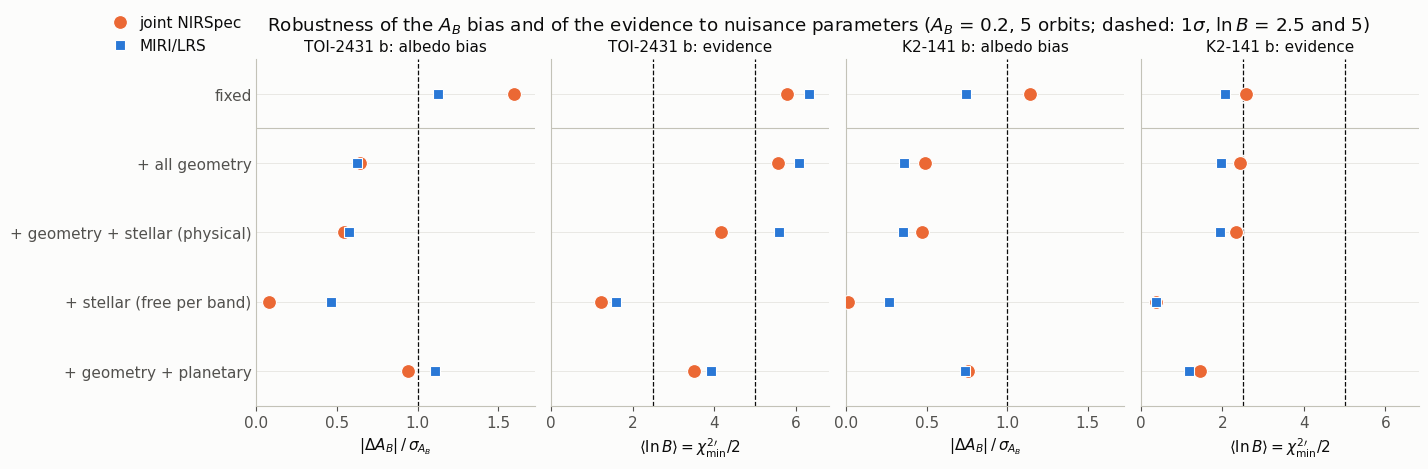

In [4]:
PAPER_MODE = False
# Horizontal dot plot of the headline rows (FIGURE_ROWS) in the primary modes (FIGURE_MODES): one line per row, the modes as markers on the same line, so a row reads left to right
ypos = {r: k for k, r in enumerate(FIGURE_ROWS)}
METRICS = (("bias_sigma", r"$|\Delta A_B|\,/\,\sigma_{A_B}$", "albedo bias", (1.,)), ("lnB_mean", r"$\langle\ln B\rangle = \chi^{2\prime}_{\min}/2$", "evidence", (2.5, 5.)))
STYLE = dict(zip(MODES, zip((C_HI, C_REDIST, INK_2), "osD", (10, 6.5, 6.5))))   # colour, marker, size: the square fits inside the circle, so coinciding points stay visible
xmax = {col: 1.08 * max(TABLES[(name, m)].set_index("row").loc[FIGURE_ROWS, col].max() for name in PLANETS for m in FIGURE_MODES) for col, *_ in METRICS}   # one x scale per quantity

fig, axs = plt.subplots(1, 2 * len(PLANETS), figsize=(15., 0.5 * len(FIGURE_ROWS) + 2.), sharey=True, gridspec_kw=dict(wspace=0.06))
for j, name in enumerate(PLANETS):
    for m, (col, xlabel, what, refs) in enumerate(METRICS):
        ax = axs[2 * j + m]
        ax.grid(False)
        for yy in ypos.values(): ax.axhline(yy, color="#e6e5e0", lw=0.6, zorder=0)    # one guide line per row
        ax.axhline(0.5, color=AXIS, lw=0.8, zorder=0)                                  # the reference row apart from the rest
        for v in refs: ax.axvline(v, color=INK, lw=0.9, ls="--", zorder=1)
        for mode in FIGURE_MODES:
            c, mk, ms = STYLE[mode]
            t = TABLES[(name, mode)].set_index("row")
            ax.plot([t.loc[r, col] for r in FIGURE_ROWS], list(ypos.values()), mk, ls="none", color=c, ms=ms, mec="white", mew=0.8, zorder=3, label=mode)
        ax.set_xlim(0., xmax[col]); ax.set_xlabel(xlabel); ax.set_title(f"{name}: {what}", fontsize=11)
axs[0].set_ylim(len(FIGURE_ROWS) - 0.5, -0.5)
axs[0].set_yticks(list(ypos.values()), FIGURE_ROWS)
for ax in axs: ax.tick_params(axis="y", length=0)   # the rows are labelled on the left only
axs[0].legend(loc="lower right", bbox_to_anchor=(-0.03, 1.), borderaxespad=0., handletextpad=0.3)   # above the row labels, where it stays clear of the data in paper mode too
fig.suptitle(rf"Robustness of the $A_B$ bias and of the evidence to nuisance parameters ($A_B$ = {A_B_true:g}, {n_orbits} orbits; dashed: $1\sigma$, $\ln B$ = 2.5 and 5)")
fig.tight_layout(rect=(0., 0., 1., 0.95))
paper_figure("nuisance_robustness", PAPER_MODE, fig=fig)
plt.show()

## 2. Why the ellipsoidal terms absorb the evidence

The whitened residual $r_\perp$ of the $A_B$-only fit next to the two ellipsoidal columns, each scaled by its own best-fit amplitude (fitted alone, with $A_B$ and the baseline). The cosines between the vectors are printed: $\cos^2$ of the angle between $r_\perp$ and a column is the share of $\chi^2_{\min}$ that the column takes directly, before $A_B$ readjusts; the cosine between a column and the $A_B$ response $j_A$ is its degeneracy with the albedo.

What to look for: the in-occultation level of $r_\perp$. Both irradiation models are zero there, so it is only the fitted baseline, and it has the sign of $-\cos 4\pi\phi$ at $\phi = 0.5$. The stellar term, present during the occultation, therefore matches the residual there as well. The planetary term is zero inside the occultation (in the figure a constant, since every column has its mean removed like the residual) and overlaps with the albedo response outside it.

TOI-2431 b, joint NIRSpec: cos(r_perp, stellar) = +0.77, cos(r_perp, planetary) = +0.34, cos(stellar, planetary) = +0.76, cos(j_A, stellar) = -0.45, cos(j_A, planetary) = -0.84
TOI-2431 b, MIRI/LRS: cos(r_perp, stellar) = +0.76, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.78, cos(j_A, stellar) = -0.47, cos(j_A, planetary) = -0.84


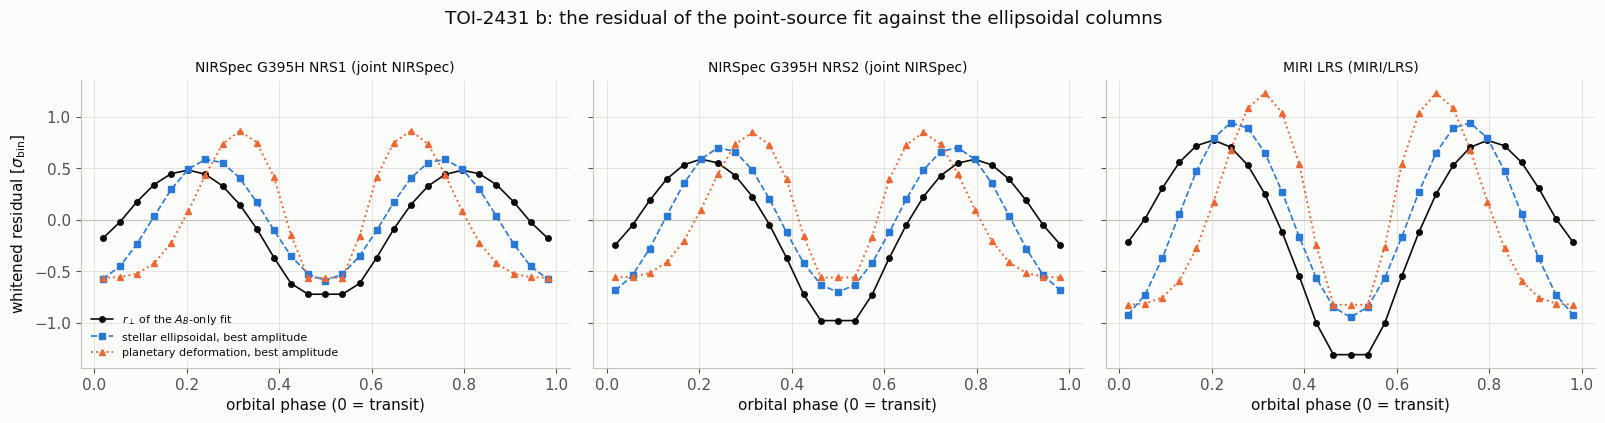

K2-141 b, joint NIRSpec: cos(r_perp, stellar) = +0.79, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.75, cos(j_A, stellar) = -0.48, cos(j_A, planetary) = -0.86
K2-141 b, MIRI/LRS: cos(r_perp, stellar) = +0.79, cos(r_perp, planetary) = +0.33, cos(stellar, planetary) = +0.78, cos(j_A, stellar) = -0.50, cos(j_A, planetary) = -0.86


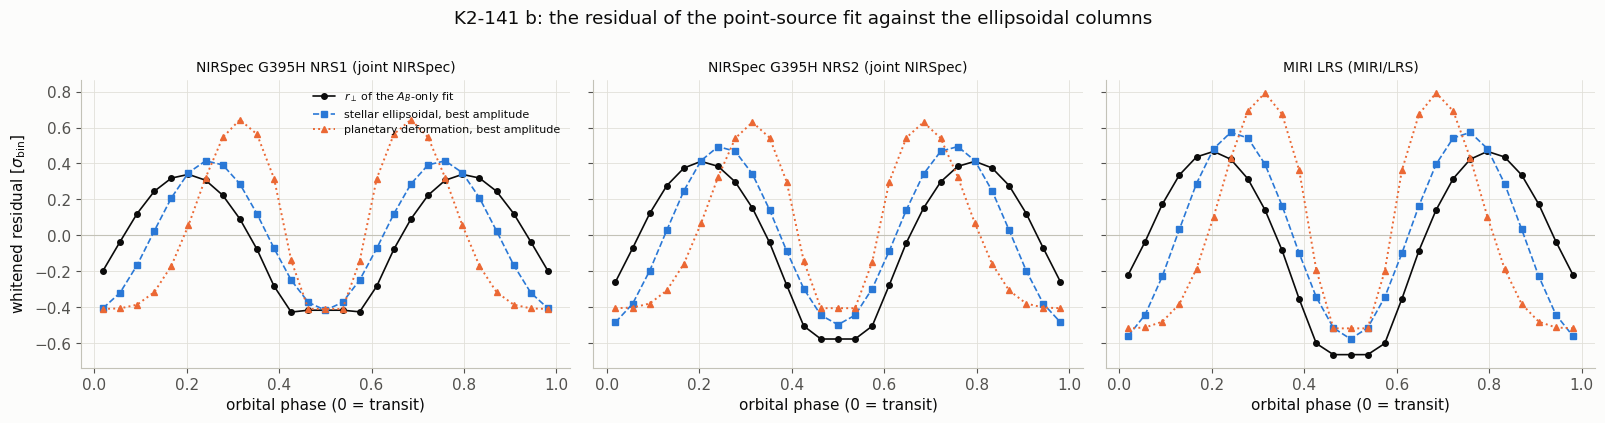

In [5]:
PAPER_MODE = False
cosang = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
for name in PLANETS:
    modes = [m for m in MODES if not m.startswith("NIRSpec +")]   # the three-detector set repeats the same blocks
    ncol = sum(len(PROBLEMS[(name, m)]["blocks"]) for m in modes)
    fig, axs = plt.subplots(1, ncol, figsize=(5.4 * ncol, 4.2), sharey=True, squeeze=False)
    k = 0
    for mode in modes:
        p = PROBLEMS[(name, mode)]
        s_st, s_pl = nuisance_solve(p, ("stellar",)), nuisance_solve(p, ("planetary",))
        y_st = sum(s_st["delta"][n] * p["columns"][n] for n in s_st["names"])
        y_pl = s_pl["delta"]["planetary"] * p["columns"]["planetary"]
        stellar_all = np.sum([p["columns"][n] for n in s_st["names"]], axis=0)   # all detectors with one amplitude, for the angles
        print(f"{name}, {mode}: cos(r_perp, stellar) = {cosang(p['y'], stellar_all):+.2f}, cos(r_perp, planetary) = {cosang(p['y'], p['columns']['planetary']):+.2f}, "
              f"cos(stellar, planetary) = {cosang(stellar_all, p['columns']['planetary']):+.2f}, cos(j_A, stellar) = {cosang(p['j_A'], stellar_all):+.2f}, cos(j_A, planetary) = {cosang(p['j_A'], p['columns']['planetary']):+.2f}")
        for blk, det in zip(p["blocks"], detectors(MODES[mode])):
            ax = axs[0, k]; k += 1
            ph = p["phase"][blk]
            ax.axhline(0., color=AXIS, lw=.8)
            ax.plot(ph, p["y"][blk], "o-", color=INK, lw=1.2, ms=4, label=r"$r_\perp$ of the $A_B$-only fit")
            ax.plot(ph, y_st[blk], "s--", color=C_REDIST, lw=1.2, ms=4, label="stellar ellipsoidal, best amplitude")
            ax.plot(ph, y_pl[blk], "^:", color=C_HI, lw=1.4, ms=4, label="planetary deformation, best amplitude")
            ax.set_title(f"{instrument_label(det, oneline=True)} ({mode})", fontsize=10); ax.set_xlabel("orbital phase (0 = transit)")
    axs[0, 0].set_ylabel(r"whitened residual [$\sigma_{\rm bin}$]"); axs[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: the residual of the point-source fit against the ellipsoidal columns", y=1.0)
    fig.tight_layout()
    paper_figure(f"nuisance_columns_{name.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()

## 3. The ellipsoidal terms: physical amplitudes and the prior of the stellar term

**Star.** $A_{\rm ell} = \alpha_{\rm ell}\,(M_p/M_\star)\,(R_\star/a)^3\sin^2 i$ with $\alpha_{\rm ell} = 0.15\,(15 + u)(1 + g)/(3 - u)$ (Morris & Naftilan 1993; Shporer 2017, PASP 129, 072001), $u$ and $g$ the linear limb-darkening and the gravity-darkening coefficient of the band. Everything but $\alpha_{\rm ell}$ is the same in every band, so the physical nuisance is one amplitude for all detectors (`stellar_shared`, band ratios `STELLAR_RATIOS`, achromatic by default). Its prior (`ellipsoidal_prior`, set in the setup cell) is centred on the truth, with the uncertainty of the expected amplitude as its width: the published errors of $M_p/M_\star$, $(R_\star/a)^3$ and $\sin^2 i$ and the spread of $\alpha_{\rm ell}$ over the $(u, g)$ bracket, taken as $1\sigma$, added in quadrature (masses and sources in the setup cell). **The band coefficients are not from a table yet**: the bracket covers infrared values of K dwarfs, to be replaced by tabulated coefficients (e.g. Claret & Bloemen 2011, A&A 529, A75). $\alpha_{\rm ell}$ depends on them only through $(15+u)/(3-u)$ and $(1+g)$; across 3–10 µm it changes by less than about 10 % ($(15+u)/(3-u)$ by at most 8 % for $\Delta u = 0.2$, $(1+g)$ by a few per cent), which the band-ratio check below covers.

**Planet.** The fitted `planetary` amplitude is $\delta = (r_1 - r_2)/r_2$, the fractional difference between the cross-sections the planet shows at quadrature ($r_1 r_3$) and at conjunction ($r_2 r_3$) ($r_1$ towards the star, $r_2$ along the orbit, $r_3$ along the orbit normal). It therefore compares with $(R_1 - R_2)/R_1$. Taş et al. (2026, Sect. 6.3.1) quote $(R_1 - R_3)/R_1$ for TOI-2431 b with a fiducial Love number $h_2 = 1$. For a synchronously rotating body in equilibrium, the tidal and the centrifugal potential displace the surface by $7/6$, $-1/3$ and $-5/6$ (in units of $h_2\zeta R_p$) along $R_1$, $R_2$, $R_3$, so $R_1 - R_2 = \tfrac34(R_1 - R_3)$, as in the Correia (2014) shape of the planetary column ($r_1 = r_2(1+3q)$, $r_3 = r_2(1-q)$); the same displacements give their $R_{\rm vol} = R_{\rm tran}(1 + \tfrac{7}{12}\delta R_p)$. The cell prints both. $h_2$ itself is uncertain (about 1.9 for a fully relaxed Earth-like interior), so the published value sets the scale, not a prior.

What to look for: per planet and mode, the table steps from no stellar term over the free amplitude per band (the worst case) and the shared amplitude without a prior (what sharing alone does) to the shared amplitude with the physical prior (the realistic case, the rows `+ stellar (physical)` of section 1), and then varies the realistic case: the prior width times `PRIOR_SCALES`, and the band ratio of the last detector by `RATIO_SHIFT`. Compare the amplitudes the free fits take with the expected one above, and how far the physical prior lets the amplitude move. The effect depends on the band: the ellipsoidal variation has the same relative amplitude in every band, while the hyper-illumination residual grows with wavelength, so a stellar term of a given size absorbs more of the NIRSpec residual than of the MIRI/LRS one.

In [6]:
AXIS_RATIO = {"TOI-2431 b": (0.087, 0.017)}  # (R1 - R3) / R1 for h2 = 1: Tas et al. 2026 (A&A 707, A238) Sect. 6.3.1
R12_OVER_R13 = 0.75                          # (R1 - R2) / (R1 - R3) of a synchronously rotating body in tidal equilibrium (see above): the planetary amplitude compares with (R1 - R2) / R1
PRIOR_SCALES = (0.5, 2.)                     # sensitivity check: the prior width of the shared stellar amplitude times these
RATIO_SHIFT = 0.15                           # sensitivity check: the band ratio of the last detector of a multi-detector mode changed by this fraction

for name in PLANETS:
    e, (q, fq) = ELLIPSOIDAL[name], mass_ratio(name)
    print(f"{name}: M_p / M_star = {q:.3e} (+- {100 * fq:.0f} %)  ->  expected stellar ellipsoidal semi-amplitude {e['A']:.2f} ppm (u in {U_RANGE}, g in {G_RANGE});  "
          f"prior sigma {e['sigma']:.2f} ppm = {100 * e['frac']:.0f} % (" + ", ".join(f"{k} {100 * v:.0f} %" for k, v in e["parts"].items()) + ")")
    if name in AXIS_RATIO: print(f"   published tidal deformation (h2 = 1): (R1 - R3)/R1 = {AXIS_RATIO[name][0]:.3f} +- {AXIS_RATIO[name][1]:.3f}  ->  (R1 - R2)/R1 = {R12_OVER_R13 * AXIS_RATIO[name][0]:.3f} +- {R12_OVER_R13 * AXIS_RATIO[name][1]:.3f}, the scale of the planetary amplitude")
    rows = []
    for mode in MODES:
        p = PROBLEMS[(name, mode)]
        flat = {**p, "priors": {k: v for k, v in p["priors"].items() if k != "stellar_shared"}}
        variants = {"none": (p, ()), "free per band": (p, ("stellar",)), "shared, flat": (flat, ("stellar_shared",)), "shared, physical prior": (p, ("stellar_shared",))}
        for f in PRIOR_SCALES:
            variants[f"shared, prior x {f:g}"] = ({**p, "priors": {**p["priors"], "stellar_shared": f * p["priors"]["stellar_shared"]}}, ("stellar_shared",))
        if len(p["blocks"]) > 1:
            for f in (1. - RATIO_SHIFT, 1. + RATIO_SHIFT):
                r = p["stellar_ratios"].copy(); r[-1] *= f
                variants[f"shared, last band ratio x {f:g}"] = ({**p, "columns": {**p["columns"], "stellar_shared": stellar_shared_column(p["columns"], r)}}, ("stellar_shared",))
        for label, (pp, nuis) in variants.items():
            s = nuisance_solve(pp, nuis)
            rows.append({"mode": mode, "stellar term": label, "sigma_A_B": s["sigma_A_B"], "bias_sigma": abs(s["A_B_fit"] - A_B_true) / s["sigma_A_B"], "lnB_mean": s["lnB_mean"],
                         "amplitude [ppm]": ", ".join(f"{s['delta'][n]:.1f} +- {s['sigma_post'][n]:.1f}" for n in s["names"]) or "-"})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
    print("   planetary amplitude fitted alone: " + ";  ".join(f"{m} {TABLES[(name, m)].set_index('row').loc['+ planetary', 'planetary']:.3f} +- {TABLES[(name, m)].set_index('row').loc['+ planetary', 'sig planetary']:.3f}" for m in MODES), "\n")

TOI-2431 b: M_p / M_star = 2.817e-05 (+- 26 %)  ->  expected stellar ellipsoidal semi-amplitude 2.96 ppm (u in (0.1, 0.3), g in (0.1, 0.4));  prior sigma 0.92 ppm = 31 % (M_p / M_star 26 %, (R_star / a)^3 6 %, sin^2 i 1 %, alpha_ell (u, g) 16 %)
   published tidal deformation (h2 = 1): (R1 - R3)/R1 = 0.087 +- 0.017  ->  (R1 - R2)/R1 = 0.065 +- 0.013, the scale of the planetary amplitude
         mode                   stellar term  sigma_A_B  bias_sigma  lnB_mean                    amplitude [ppm]
joint NIRSpec                           none     0.0266         1.6      5.79                                  -
joint NIRSpec                  free per band     0.0298      0.0749      1.21             3.0 +- 1.5, 4.6 +- 1.8
joint NIRSpec                   shared, flat     0.0298       0.089      1.45                         3.6 +- 1.2
joint NIRSpec         shared, physical prior     0.0278        1.01      4.21                         1.3 +- 0.7
joint NIRSpec            shared, prior x 0.5 

## 4. Checks

**Step size of the geometry columns.** The same tables with every finite-difference step doubled (`NUISANCE_STEPS` × 2): the relative change of each column and the largest relative change of $\sigma_{A_B}$ and $\chi^{2\prime}_{\min}$ over all rows.

**Nonlinear refit.** For the cases and rows of `NL_CHECKS` (TOI-2431 b in MIRI/LRS, and in the joint NIRSpec fit the rows whose columns combine detectors or parameters: $b$, the shared stellar term), the full nonlinear least-squares fit (`nuisance_fit_nonlinear`: the point-source model re-evaluated at every step, $i$ from $b$ where $b$ is fitted, priors as residual rows, baselines by mean removal) against the linear rows: $\hat A_B$, $\sigma_{A_B}$ from the Jacobian at the solution, and $\chi^2_{\min}$.

What to look for: the linear and the nonlinear numbers agree where the fit moves little (geometry rows). Where an ellipsoidal term shifts $A_B$ by more than its $\sigma$, the response to $A_B$ is no longer linear over the shift ($T \propto (1-A_B)^{1/4}$) and the two differ in $\hat A_B$ and $\sigma_{A_B}$, while $\chi^2_{\min}$, the quantity the evidence rests on, stays close.

In [7]:
def case_2h(name, mode):
    pl = hi_planets_by_name(name)
    c = retrieval_cfg(cfg, pl, MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_problem(c, truth, priors=PRIORS[name], stellar_ratios=STELLAR_RATIOS, steps={k: 2. * v for k, v in NUISANCE_STEPS.items()}, **kw)

P2 = dict(zip(CASES, pmap(case_2h, CASES)))
print(f"steps {NUISANCE_STEPS} against twice these:")
for k in CASES:
    t1, t2 = TABLES[k], nuisance_table(P2[k], A_B_true, ROWS[k[0]])
    cols = ", ".join(f"{n} {np.linalg.norm(PROBLEMS[k]['columns'][n] - P2[k]['columns'][n]) / np.linalg.norm(PROBLEMS[k]['columns'][n]):.1e}" for n in GEOM)
    print(f"   {k[0]:11s} {k[1]:14s} relative change of the columns: {cols};  max over rows: sigma_A_B {np.max(np.abs(t2['sigma_A_B'] / t1['sigma_A_B'] - 1.)):.1e}, chi2 {np.max(np.abs(t2['chi2'] / t1['chi2'] - 1.)):.1e}")

steps {'a_rs': 0.005, 'rp_rs': 0.0001, 'incl': 0.2} against twice these:
   TOI-2431 b  joint NIRSpec  relative change of the columns: a_rs 4.2e-03, rp_rs 1.3e-06, incl 1.5e-03;  max over rows: sigma_A_B 2.7e-03, chi2 1.4e-03
   TOI-2431 b  MIRI/LRS       relative change of the columns: a_rs 6.0e-03, rp_rs 1.6e-06, incl 1.7e-03;  max over rows: sigma_A_B 1.1e-03, chi2 1.1e-03
   TOI-2431 b  NIRSpec + LRS  relative change of the columns: a_rs 4.6e-03, rp_rs 1.4e-06, incl 1.6e-03;  max over rows: sigma_A_B 3.6e-03, chi2 1.9e-03
   K2-141 b    joint NIRSpec  relative change of the columns: a_rs 6.8e-03, rp_rs 6.7e-08, incl 2.2e-03;  max over rows: sigma_A_B 3.3e-04, chi2 4.5e-04
   K2-141 b    MIRI/LRS       relative change of the columns: a_rs 8.5e-03, rp_rs 1.1e-07, incl 2.9e-03;  max over rows: sigma_A_B 1.5e-04, chi2 3.2e-04
   K2-141 b    NIRSpec + LRS  relative change of the columns: a_rs 7.1e-03, rp_rs 7.5e-08, incl 2.3e-03;  max over rows: sigma_A_B 3.3e-04, chi2 5.2e-04


In [8]:
# The linear rows against nonlinear least-squares fits: every row of interest for TOI-2431 b in MIRI/LRS, and for the joint NIRSpec fit the rows whose columns combine detectors (b, the shared stellar term)
NL_CHECKS = {("TOI-2431 b", "MIRI/LRS"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)", "+ planetary", "+ geometry + planetary"],
             ("TOI-2431 b", "joint NIRSpec"): ["+ all geometry", "+ stellar (physical)", "+ geometry + stellar (physical)", "+ stellar (free per band)"]}
NL_JOBS = [(key, label) for key, labels in NL_CHECKS.items() for label in labels]

def nonlinear(key, label):
    name, mode = key
    c = retrieval_cfg(cfg, hi_planets_by_name(name), MODES[mode])
    truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
    return nuisance_fit_nonlinear(c, truth, ROWS[name][label], priors=PROBLEMS[key]["priors"], stellar_ratios=STELLAR_RATIOS, **kw)

NL = dict(zip(NL_JOBS, pmap(nonlinear, NL_JOBS)))
for key, labels in NL_CHECKS.items():
    p = PROBLEMS[key]
    lin = {label: nuisance_solve(p, ROWS[key[0]][label]) for label in labels}
    print(f"{key[0]}, {key[1]}: linear rows against the nonlinear least-squares fit")
    print(pd.DataFrame([{"row": label, "A_B lin": lin[label]["A_B_fit"], "A_B nonlin": NL[(key, label)]["A_B_fit"], "sigma lin": lin[label]["sigma_A_B"], "sigma nonlin": NL[(key, label)]["sigma_A_B"],
                         "chi2 lin": lin[label]["chi2"], "chi2 nonlin": NL[(key, label)]["chi2"], "nfev": NL[(key, label)]["nfev"]} for label in labels]).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    print("fitted nuisances, linear | nonlinear (value +- sigma):")
    for label in labels:
        nl = NL[(key, label)]
        print(f"   {label}: " + ";  ".join(f"{n} {p['values'].get(n, 0.) + lin[label]['delta'][n]:.5g} +- {lin[label]['sigma_post'][n]:.2g} | {nl['values'][n]:.5g} +- {nl['sigma_post'][n]:.2g}" for n in lin[label]["names"]))
    print()

TOI-2431 b, MIRI/LRS: linear rows against the nonlinear least-squares fit
                            row  A_B lin  A_B nonlin  sigma lin  sigma nonlin  chi2 lin  chi2 nonlin  nfev
                 + all geometry   0.1516      0.1507     0.0774       0.07664     12.17        12.17    20
           + stellar (physical)   0.1505      0.1505    0.05397       0.05351     11.53        11.53    26
+ geometry + stellar (physical)   0.1556      0.1557    0.07751       0.07643      11.2         11.2    16
      + stellar (free per band)   0.2277      0.2246    0.06022       0.05591     3.172        3.172    12
                    + planetary   0.3187      0.3112    0.09765       0.08885     7.892        7.927    20
         + geometry + planetary   0.3267      0.3184     0.1143        0.1009     7.837        7.867    18
fitted nuisances, linear | nonlinear (value +- sigma):
   + all geometry: a_rs|b 2.0691 +- 0.03 | 2.0689 +- 0.03;  rp_rs 0.021307 +- 0.00013 | 0.021305 +- 0.00013;  b 0.57548 +-